# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('C:/Users/Nikhilesh/data-viz-class-material-w2026/data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


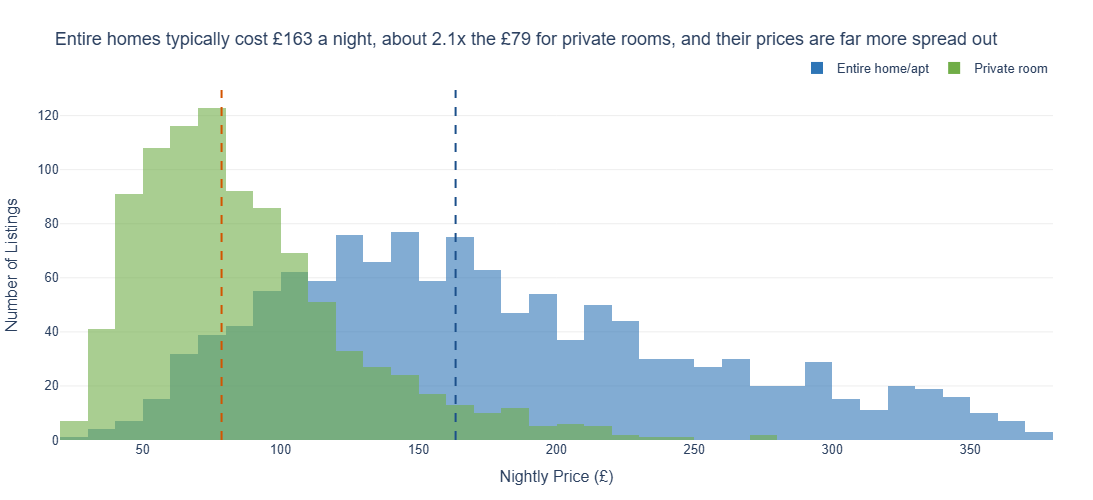

In [3]:
# Task 1
df_rt = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])].copy()

# Median of each room type (computed on the capped data)
med_entire  = df_rt.loc[df_rt['room_type'] == 'Entire home/apt', 'price'].median()
med_private = df_rt.loc[df_rt['room_type'] == 'Private room', 'price'].median()

fig = px.histogram(
    data_frame=df_rt,
    x='price',
    color='room_type',
    barmode='overlay',                     # bars drawn on top of each other
    opacity=0.6,                           # so both distributions stay visible
    nbins=50,
    color_discrete_map={                   # same colours as the box plot example
        'Entire home/apt': '#2E75B6',
        'Private room': '#70AD47'
    },
    category_orders={'room_type': ['Entire home/apt', 'Private room']},
    labels={'price': 'Nightly Price (£)', 'count': 'Number of Listings', 'room_type': 'Room type'},
    height=500
)

# Median line for Entire home/apt (dark blue)
fig.add_vline(x=med_entire, line_dash='dash', line_color='#1B4F8A', line_width=2,
              annotation=dict(
                  text=f'<b>Entire home median: £{med_entire:.0f}',
                  font=dict(color='#1B4F8A', size=12),
                  xanchor='left', yanchor='top', xshift=8))

# Median line for Private room (dark orange, a different colour so the lines are easy to tell apart)
fig.add_vline(x=med_private, line_dash='dash', line_color='#D35400', line_width=2,
              annotation=dict(
                  text=f'<b>Private room median: £{med_private:.0f}',
                  font=dict(color='#D35400', size=12),
                  xanchor='right', yanchor='top', xshift=-8))

fig.update_layout(
    title=(f'Entire homes typically cost £{med_entire:.0f} a night, about '
           f'{med_entire/med_private:.1f}x the £{med_private:.0f} for private rooms, '
           f'and their prices are far more spread out'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of Listings'),
    xaxis=dict(showgrid=False, title='Nightly Price (£)'),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=60, r=40, t=90, b=60),
    annotations=[dict(
        text=f'Note: prices capped at the 95th percentile (£{p95:.0f}). Shared rooms excluded (too few observations).',
        xref='paper', yref='paper', x=0, y=-0.18, showarrow=False,
        font=dict(size=11, color='#666666'), xanchor='left')]
)
fig.show()


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

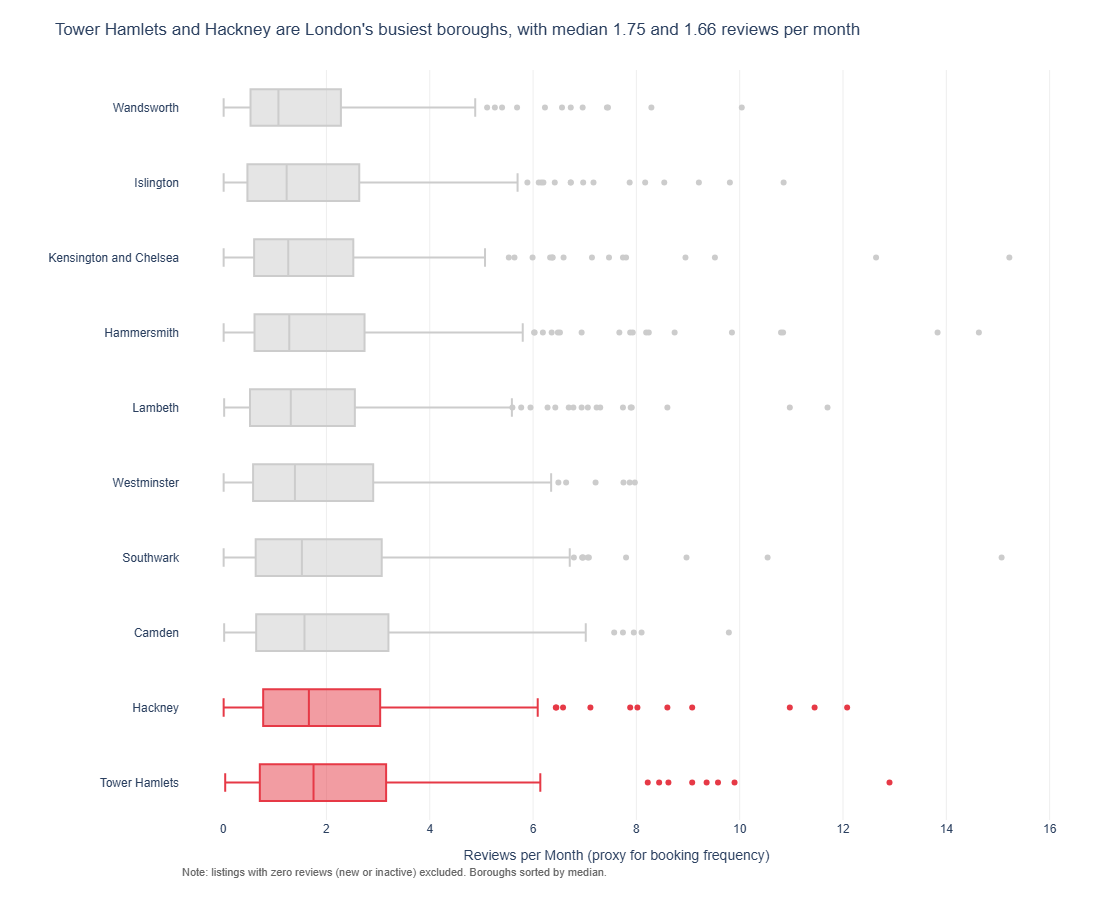

In [4]:
# Task 2
df_act = df[df['reviews_per_month'].notna() & (df['reviews_per_month'] > 0)].copy()

# Median reviews per month by borough, sorted ascending
# (plotly draws the first category at the bottom, so the highest median ends up at the top)
med_rev = df_act.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=True)
med_order = med_rev.index.tolist()

# Two most active boroughs = last two in the ascending order
top1, top2 = med_order[-1], med_order[-2]

# One colour per borough: highlight the top two, grey for the rest
colour_map = {b: '#CCCCCC' for b in med_order}
colour_map[top1] = '#E63946'
colour_map[top2] = '#E63946'

fig = px.box(
    data_frame=df_act,
    y='neighbourhood',                     # horizontal: long borough names stay readable
    x='reviews_per_month',
    color='neighbourhood',
    orientation='h',
    color_discrete_map=colour_map,
    category_orders={'neighbourhood': med_order},
    points='outliers',                     # outliers as individual points
    labels={'reviews_per_month': 'Reviews per Month', 'neighbourhood': ''},
    height=900, width=1000
)

fig.update_layout(
    title=(f'{top1} and {top2} are London\'s busiest boroughs, with median '
           f'{med_rev[top1]:.2f} and {med_rev[top2]:.2f} reviews per month'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=12),
    xaxis=dict(gridcolor='#EEEEEE', title='Reviews per Month (proxy for booking frequency)'),
    yaxis=dict(showgrid=False, title=''),
    showlegend=False,
    margin=dict(l=180, r=40, t=70, b=80),
    annotations=[dict(
        text='Note: listings with zero reviews (new or inactive) excluded. Boroughs sorted by median.',
        xref='paper', yref='paper', x=0, y=-0.08, showarrow=False,
        font=dict(size=11, color='#666666'), xanchor='left')]
)
fig.show()
